# Register Fault Injection — Resilience Analysis
**Model:** MNIST LeNet-5 (INT8 quantized TFLite)  
**Target:** RISC-V registers (transient bit-flip)  
**Campaign:** `registerfi_image_classification_fashsion_mnist_transient`  
**Sampling:** Stratified per operator — 90% confidence, 5% margin

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "figure.figsize": (10, 5)})

RUN_DIR = Path(".")  # notebook lives inside the run directory

SEVERITY_ORDER = ["Masked", "Good", "Acceptable", "Warning", "Critical", "Crash"]
SEVERITY_COLORS = {
    "Masked": "#4CAF50",
    "Good": "#81C784",
    "Acceptable": "#FFC107",
    "Warning": "#FF9800",
    "Critical": "#F44336",
    "Crash": "#B71C1C",
}

CRITICAL_SET = {"Critical", "Crash"}
DEGRADED_SET = {"Warning", "Critical", "Crash"}

## 1. Data Loading

In [2]:
df = pd.read_csv(RUN_DIR / "classified_results.csv")
pop = pd.read_csv(RUN_DIR / "register_population.csv")
sel = pd.read_csv(RUN_DIR / "selected_register_faults.csv")
sel_by_layer = pd.read_csv(RUN_DIR / "selected_register_faults_by_layer.csv")
pop_by_op = pd.read_csv(RUN_DIR / "register_population_by_operator.csv")
operators = pd.read_csv(RUN_DIR / "all_operator_instances.csv")

import json
with open(RUN_DIR / "run_manifest.json") as f:
    manifest = json.load(f)

# Merge register metadata into classified results
reg_meta = sel[["fault_id", "register_name", "register_class", "register_id"]].drop_duplicates("fault_id")
df = df.merge(reg_meta, on="fault_id", how="left", suffixes=("", "_meta"))

# Ensure register_name and register_class columns are populated
if "register_name_meta" in df.columns:
    df["register_name"] = df["register_name"].fillna(df["register_name_meta"])
if "register_class" not in df.columns and "register_class_meta" in df.columns:
    df["register_class"] = df["register_class_meta"]

print(f"Total classified results : {len(df):,}")
print(f"Unique faults injected   : {df['fault_id'].nunique():,}")
print(f"Images per fault         : {len(df) // df['fault_id'].nunique()}")
print(f"Population size          : {len(pop):,}")
print(f"Operators targeted       : {df['operator_index'].nunique()}")
print(f"Registers targeted       : {df['register_name'].nunique()}")
print(f"Fault model              : {manifest.get('campaign_type', 'register')}")
print(f"Fault duration           : {manifest.get('fault_duration', 'transient')}")
df.head(3)

Total classified results : 82,500
Unique faults injected   : 825
Images per fault         : 100
Population size          : 2,080
Operators targeted       : 5
Registers targeted       : 13
Fault model              : register
Fault duration           : transient


,event,phase,mode,fault_model,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,...,delay_us,bit_index,mean_duration_us,samples,golden_pred_class_ref,golden_top1_prob_ref,fault_class,register_name_meta,register_class,register_id_meta
0,result,fault,fault,register,1.0,0.0,9.0,9.0,0.921875,9.0,...,10858.0,1.0,NaN,NaN,9.0,0.921875,Masked,ra,caller_saved,0
1,result,fault,fault,register,1.0,1.0,8.0,8.0,0.996094,8.0,...,10858.0,1.0,NaN,NaN,8.0,0.996094,Masked,ra,caller_saved,0
2,result,fault,fault,register,1.0,2.0,7.0,7.0,0.996094,7.0,...,10858.0,1.0,NaN,NaN,7.0,0.996094,Masked,ra,caller_saved,0


## 2. Overall Fault Classification Distribution

,Count,Percentage (%)
fault_class,,
Masked,45065.0,54.62
Good,107.0,0.13
Acceptable,1993.0,2.42
Warning,1901.0,2.30
Critical,4258.0,5.16
Crash,29176.0,35.36
TOTAL,82500.0,100.00


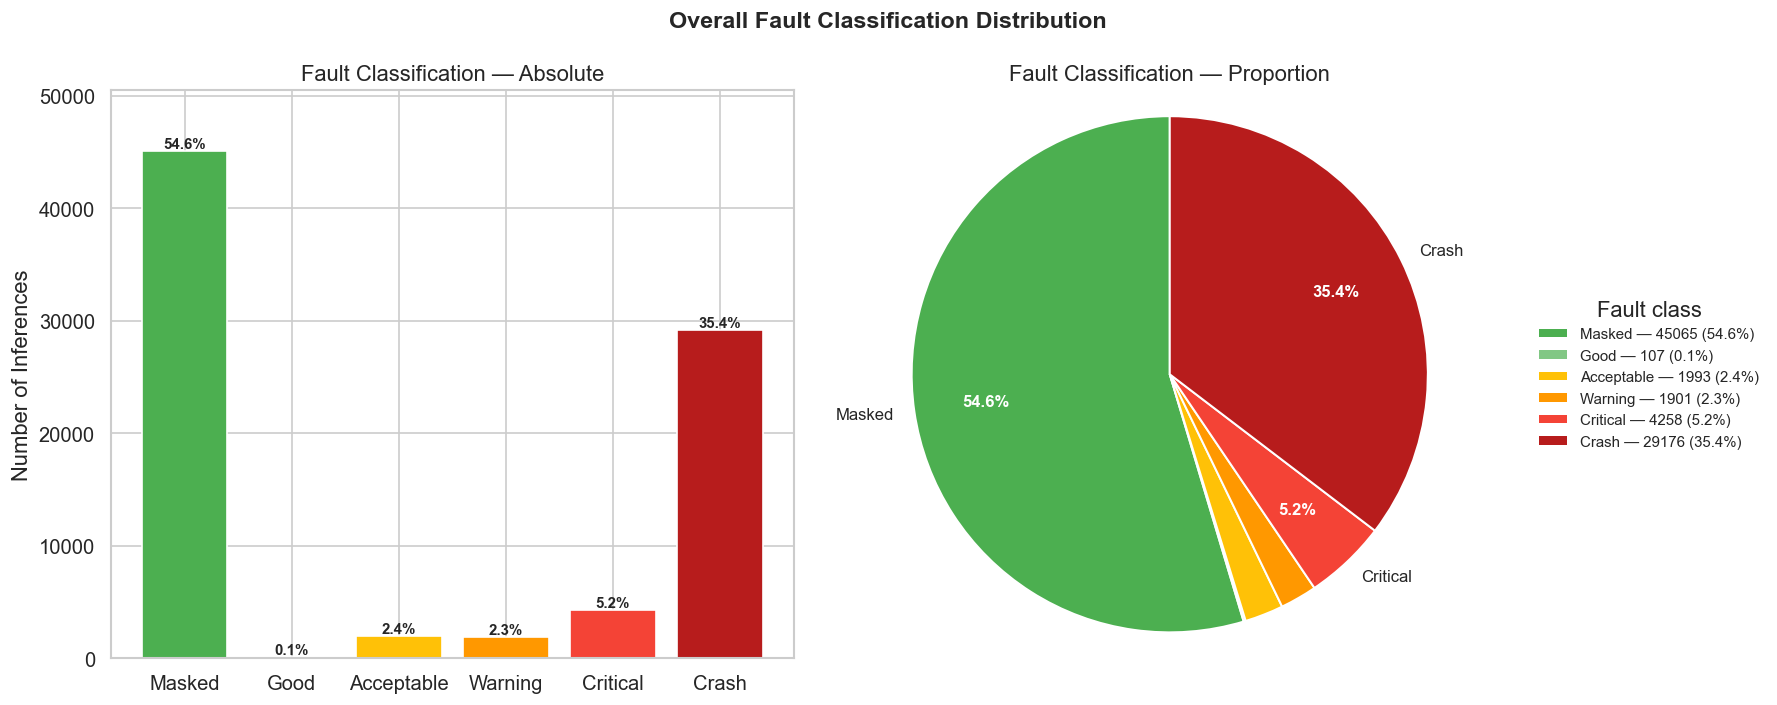

In [3]:
fc_counts = df["fault_class"].value_counts()
fc_ordered = fc_counts.reindex(SEVERITY_ORDER).dropna().astype(int)
fc_pct = fc_ordered / len(df) * 100

summary_table = pd.DataFrame({"Count": fc_ordered, "Percentage (%)": fc_pct.round(2)})
summary_table.loc["TOTAL"] = [len(df), 100.0]
display(summary_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar chart
colors = [SEVERITY_COLORS.get(c, "#999") for c in fc_ordered.index]
bars = axes[0].bar(fc_ordered.index, fc_ordered.values, color=colors, edgecolor="white")
for bar, pct in zip(bars, fc_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f"{pct:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Number of Inferences")
axes[0].set_title("Fault Classification — Absolute")
axes[0].margins(y=0.12)

# Pie chart — rótulos só para fatias >= 3%, demais vão só na legenda
THRESH = 3.0  # %

def _autopct(pct):
    return f"{pct:.1f}%" if pct >= THRESH else ""

pie_labels = [name if pct >= THRESH else "" for name, pct in zip(fc_ordered.index, fc_pct.values)]

wedges, texts, autotexts = axes[1].pie(
    fc_ordered.values,
    labels=pie_labels,
    colors=colors,
    autopct=_autopct,
    startangle=90,
    pctdistance=0.72,
    labeldistance=1.08,
    wedgeprops=dict(edgecolor="white", linewidth=1.2),
    textprops=dict(fontsize=10),
)
for t in autotexts:
    t.set_fontweight("bold")
    t.set_color("white")

axes[1].set_title("Fault Classification — Proportion")
axes[1].axis("equal")

# Legenda completa (inclui fatias pequenas omitidas do gráfico)
legend_labels = [f"{name} — {cnt} ({pct:.1f}%)"
                 for name, cnt, pct in zip(fc_ordered.index, fc_ordered.values, fc_pct.values)]
axes[1].legend(
    wedges, legend_labels,
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=9,
    frameon=False,
)

fig.suptitle("Overall Fault Classification Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_overall_classification.png", bbox_inches="tight")
plt.show()

## 3. Resilience per Register

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
register_name,,,,,,,,
ra,6500,600,0,0,0,5900,0.9077,0.9077
s3,6600,2096,73,97,590,3741,0.6562,0.6709
s0,6000,2433,162,201,422,2775,0.5328,0.5663
s8,6500,2934,172,193,583,2615,0.4920,0.5217
s2,6700,2738,294,654,1186,1800,0.4457,0.5433
s1,5300,2480,279,203,415,1900,0.4368,0.4751
s9,5900,3457,3,0,0,2440,0.4136,0.4136
s11,6500,3789,33,56,115,2506,0.4032,0.4118
s10,6600,4293,97,10,224,1971,0.3326,0.3341


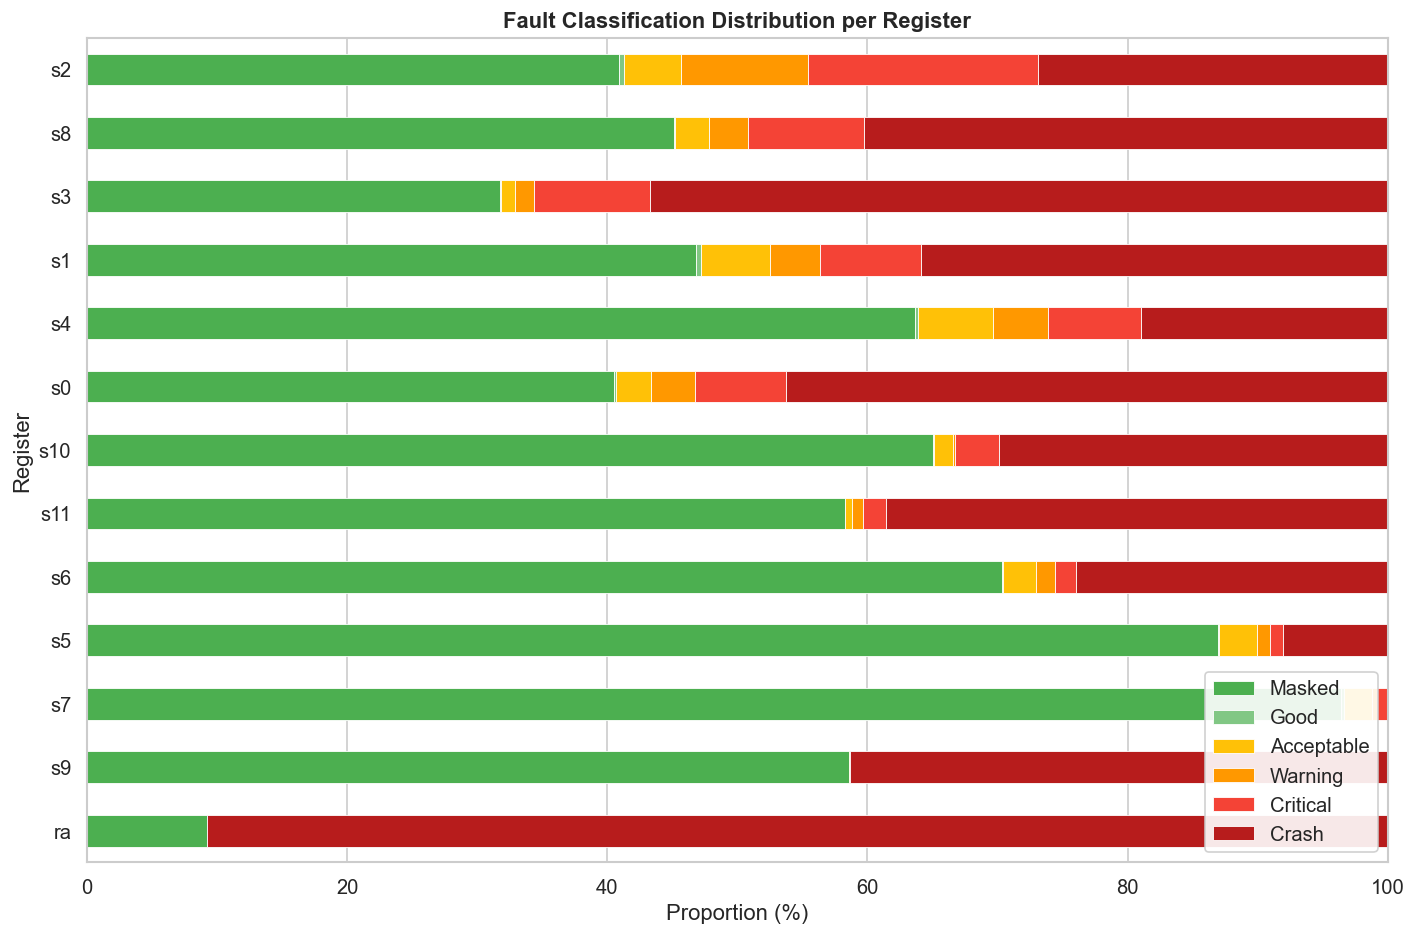

In [4]:
# Aggregate fault class distribution per register
reg_fc = df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
reg_fc = reg_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
reg_fc["total"] = reg_fc.sum(axis=1)
reg_fc["critical_rate"] = (reg_fc.get("Critical", 0) + reg_fc.get("Crash", 0)) / reg_fc["total"]
reg_fc["degraded_rate"] = reg_fc[[c for c in DEGRADED_SET if c in reg_fc.columns]].sum(axis=1) / reg_fc["total"]
reg_fc = reg_fc.sort_values("critical_rate", ascending=False)

display(reg_fc[["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]].round(4))

# Stacked bar — percentage per register
reg_pct = reg_fc[SEVERITY_ORDER].div(reg_fc["total"], axis=0) * 100
reg_pct_sorted = reg_pct.sort_values("Critical", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))
reg_pct_sorted.plot.barh(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white", linewidth=0.5,
)
ax.set_xlabel("Proportion (%)")
ax.set_ylabel("Register")
ax.set_title("Fault Classification Distribution per Register", fontweight="bold")
ax.legend(loc="lower right", framealpha=0.9)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_register.png", bbox_inches="tight")
plt.show()

## 4. Resilience per Register Class
Registers are grouped by their RISC-V ABI classification: **caller-saved** (temporary), **callee-saved** (preserved), and **special** (sp, gp, tp, ra).

fault_class,Masked,Good,Acceptable,Warning,Critical,Crash,total,critical_rate,degraded_rate
register_class,,,,,,,,,
callee_saved,44465,107,1993,1901,4258,23276,76000,0.3623,0.3873
caller_saved,600,0,0,0,0,5900,6500,0.9077,0.9077


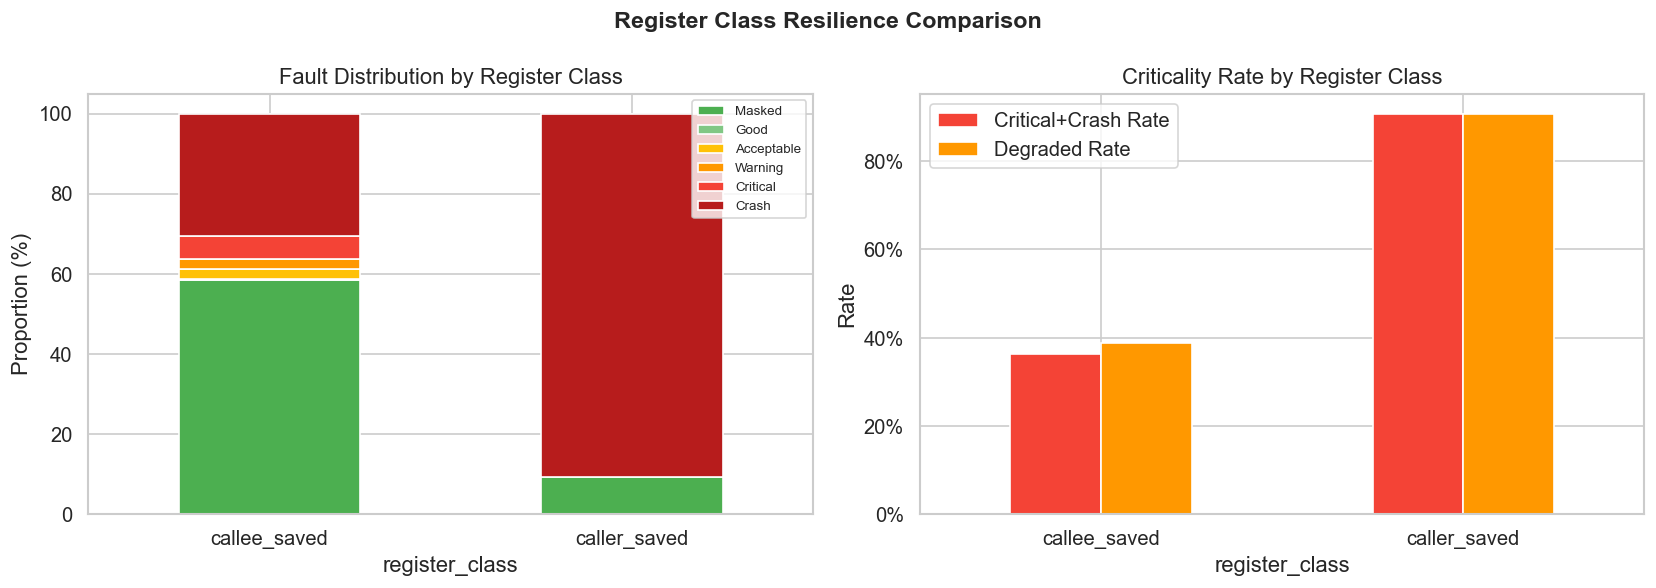

In [5]:
cls_fc = df.groupby("register_class")["fault_class"].value_counts().unstack(fill_value=0)
cls_fc = cls_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
cls_fc["total"] = cls_fc.sum(axis=1)
cls_fc["critical_rate"] = (cls_fc.get("Critical", 0) + cls_fc.get("Crash", 0)) / cls_fc["total"]
cls_fc["degraded_rate"] = cls_fc[[c for c in DEGRADED_SET if c in cls_fc.columns]].sum(axis=1) / cls_fc["total"]

display(cls_fc.round(4))

cls_pct = cls_fc[SEVERITY_ORDER].div(cls_fc["total"], axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cls_pct.plot.bar(
    stacked=True, ax=axes[0],
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
axes[0].set_ylabel("Proportion (%)")
axes[0].set_title("Fault Distribution by Register Class")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(axis="x", rotation=0)

# Critical + Crash rate comparison
cls_crit = cls_fc[["critical_rate", "degraded_rate"]].copy()
cls_crit.columns = ["Critical+Crash Rate", "Degraded Rate"]
cls_crit.plot.bar(ax=axes[1], color=["#F44336", "#FF9800"], edgecolor="white")
axes[1].set_ylabel("Rate")
axes[1].set_title("Criticality Rate by Register Class")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=0)

fig.suptitle("Register Class Resilience Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_register_class_resilience.png", bbox_inches="tight")
plt.show()

## 5. Resilience per Operator (Layer)

In [6]:
df.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'elapsed_ms',
       'timeout_ms', 'boot_seen', 'result_seen', 'job_ack_seen',
       'recovery_method', 'inferred', 'operator_index', 'operator_name',
       'register_id', 'register_name', 'time_slot_index', 'time_slot_count',
       'delay_us', 'bit_index', 'mean_duration_us', 'samples',
       'golden_pred_class_ref', 'golden_top1_prob_ref', 'fault_class',
       'register_name_meta', 'register_class', 'register_id_meta'],
      dtype='object')

In [7]:
df['operator_index'].value_counts()

operator_index
0.0     16500
3.0     16500
6.0     16500
12.0    16500
14.0    16500
Name: count, dtype: int64

In [8]:
d = pd.read_csv('results.csv')

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\1667207595.py:1: DtypeWarning: Columns (15,16,17,19) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv('results.csv')


In [9]:
d.columns

Index(['event', 'phase', 'mode', 'fault_model', 'fault_id', 'image_id',
       'label', 'pred_class', 'top1_prob', 'golden_pred_class',
       'golden_top1_prob', 'status', 'injection_status', 'elapsed_ms',
       'timeout_ms', 'boot_seen', 'result_seen', 'job_ack_seen',
       'recovery_method', 'inferred', 'operator_index', 'operator_name',
       'register_id', 'register_name', 'time_slot_index', 'time_slot_count',
       'delay_us', 'bit_index', 'mean_duration_us', 'samples'],
      dtype='object')

In [10]:
d['operator_name'].value_counts()

operator_name
CONV_2D            49503
FULLY_CONNECTED    33002
Name: count, dtype: int64

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
CONV_2D,49500,24494,1003,514,937,22475,0.4730,0.4834
FULLY_CONNECTED,33000,20571,990,1387,3321,6701,0.3037,0.3457


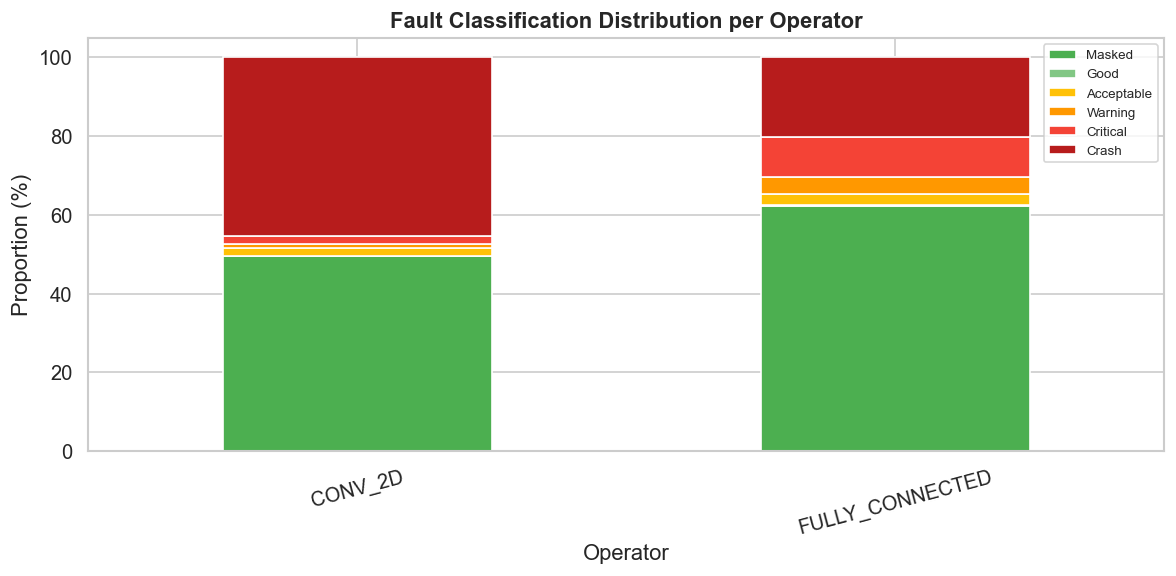

In [11]:
import numpy as np

# Usa apenas o nome real do operador
df["op_label"] = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .fillna("Unknown")
    .replace("", "Unknown")
)

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

op_fc = op_fc.sort_values("critical_rate", ascending=False)

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den, axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator")
ax.set_title("Fault Classification Distribution per Operator", fontweight="bold")
ax.legend(loc="upper right", fontsize=8)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 6. Register × Operator Criticality Heatmap

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\2925067920.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  heatmap_data = df.groupby(["register_name", "op_label"]).apply(critical_rate).unstack(fill_value=0)
C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\2925067920.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reg_order = df.groupby("register_name").apply(critical_rate).sort_values(ascending=F

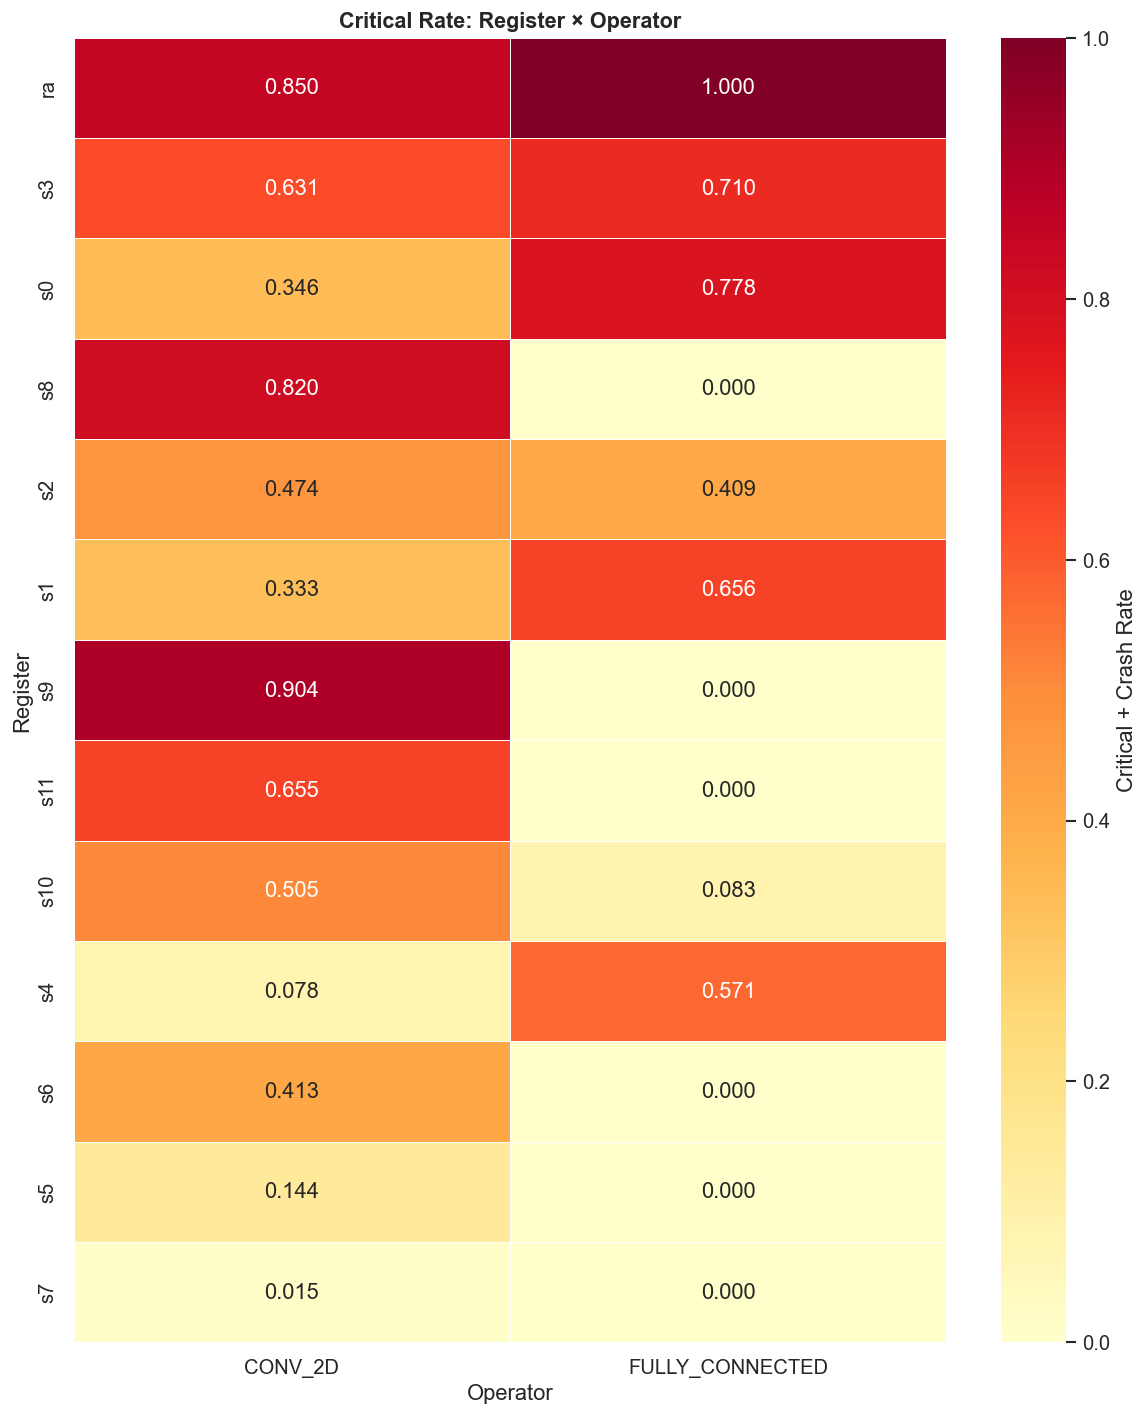

In [12]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

heatmap_data = df.groupby(["register_name", "op_label"]).apply(critical_rate).unstack(fill_value=0)

# Sort registers by overall critical rate
reg_order = df.groupby("register_name").apply(critical_rate).sort_values(ascending=False).index
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3847261106.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(critical_rate)
C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3847261106.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("register_name").apply(critical_rate)


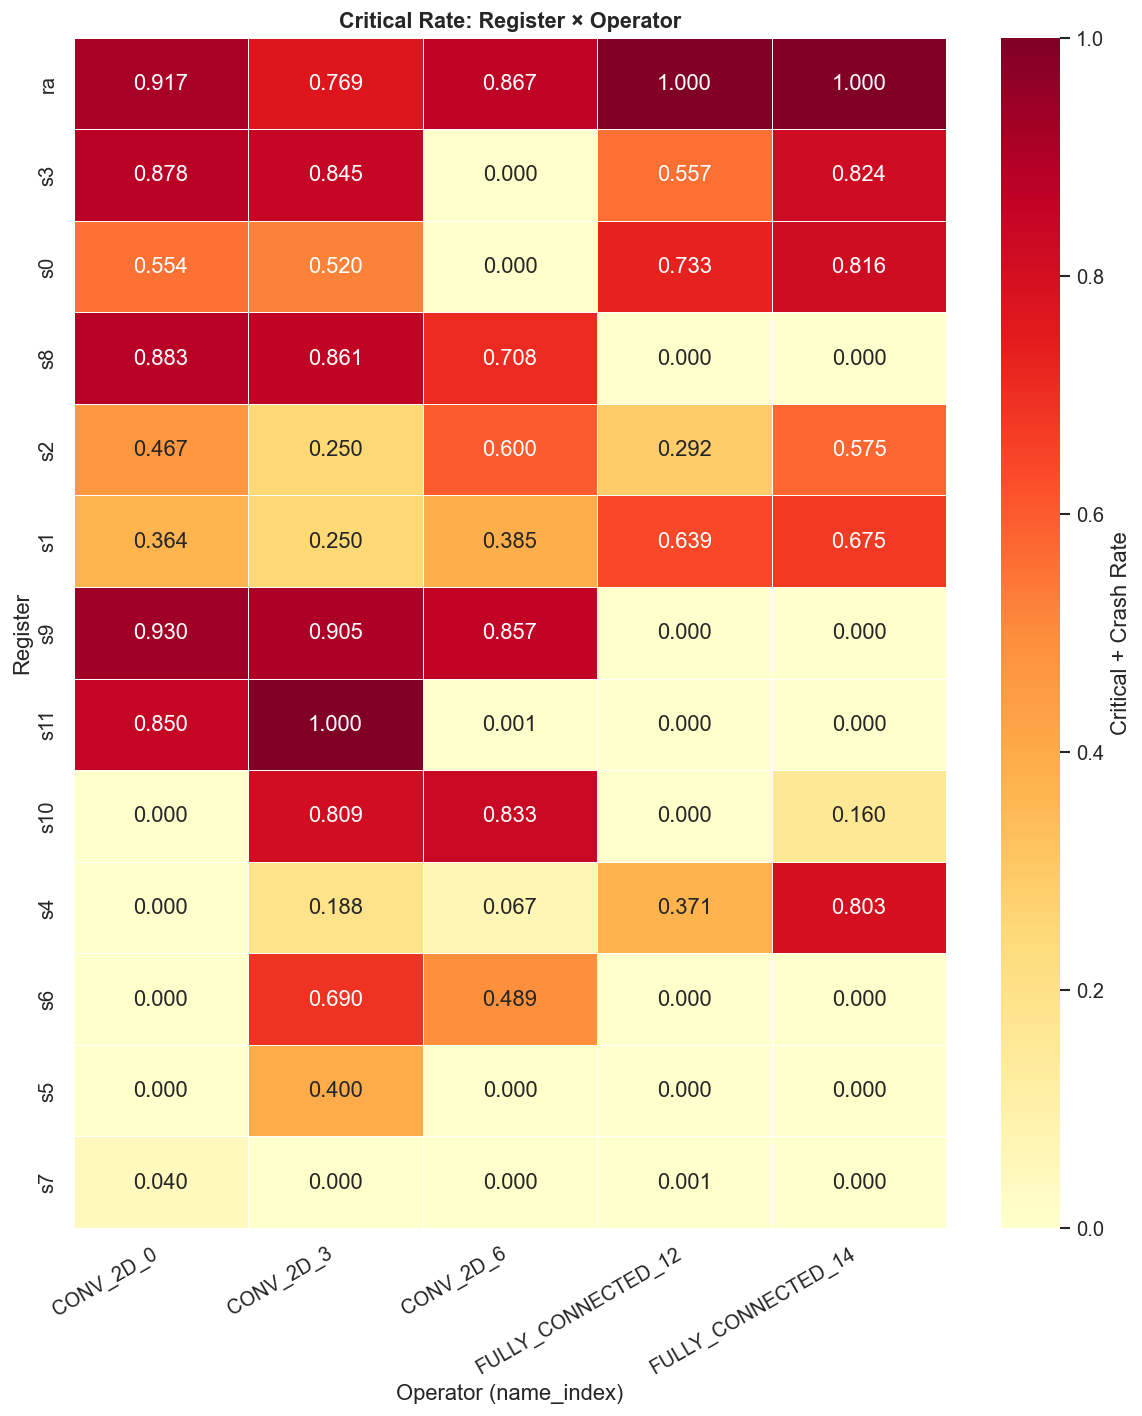

In [13]:
def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

# Build "operator_name_operator_index" label (e.g. CONV_2D_0, CONV_2D_2)
op_name = (
    df["operator_name"].astype("string").str.strip()
    .replace("", pd.NA).fillna("Unknown")
)
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64").astype("string").fillna("NA")
)
df["op_full"] = op_name + "_" + op_idx

heatmap_data = (
    df.groupby(["register_name", "op_full"])
      .apply(critical_rate)
      .unstack(fill_value=0)
)

# Order columns by numeric operator_index when possible
col_order = sorted(
    heatmap_data.columns,
    key=lambda c: (int(c.rsplit("_", 1)[1]) if c.rsplit("_", 1)[1].isdigit() else 10**9, c),
)
heatmap_data = heatmap_data[col_order]

# Sort registers by overall critical rate
reg_order = (
    df.groupby("register_name").apply(critical_rate)
      .sort_values(ascending=False).index
)
heatmap_data = heatmap_data.reindex(reg_order)

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Operator (name_index)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_operator.png", bbox_inches="tight")
plt.show()

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
0_CONV_2D,16500,8873,235,118,430,6825,0.4397,0.4468
3_CONV_2D,16500,5708,395,235,374,9749,0.6135,0.6278
6_CONV_2D,16500,9913,373,161,133,5901,0.3657,0.3755
12_FULLY_CONNECTED,16500,9974,808,1221,771,3701,0.2710,0.3450
14_FULLY_CONNECTED,16500,10597,182,166,2550,3000,0.3364,0.3464


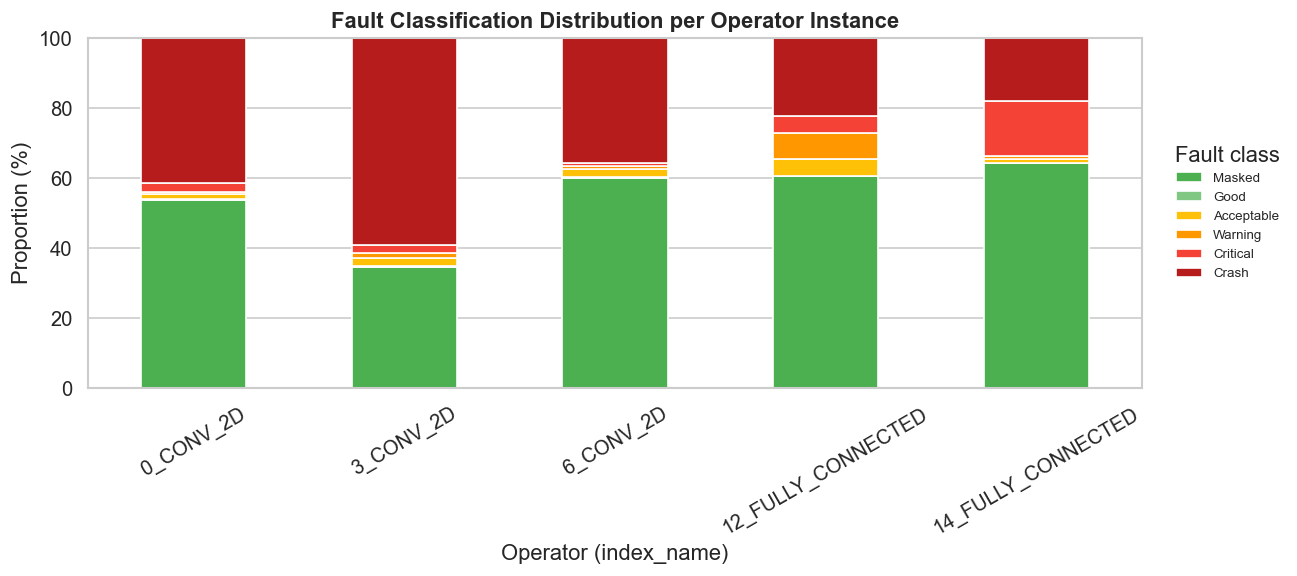

In [14]:
import numpy as np

# Combina operator_index + operator_name para distinguir instâncias do mesmo operador
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .fillna("NA")
)
op_name = (
    df["operator_name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
df["op_label"] = op_idx + "_" + op_name

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)

op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)

op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

# Ordena por op_index numérico (quando disponível) para manter ordem natural da rede
def _sort_key(label: str):
    head = label.split("_", 1)[0]
    try:
        return (0, int(head))
    except ValueError:
        return (1, label)

op_fc = op_fc.loc[sorted(op_fc.index, key=_sort_key)]

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den.loc[op_fc.index], axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(11, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator (index_name)")
ax.set_title("Fault Classification Distribution per Operator Instance", fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(
    title="Fault class",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    frameon=False,
)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 7. Bit-Position Vulnerability Analysis
Evaluates whether higher-order bits (MSB) lead to more critical failures than lower-order bits (LSB).

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3403739046.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bit_fc = df.groupby("bit_index").apply(


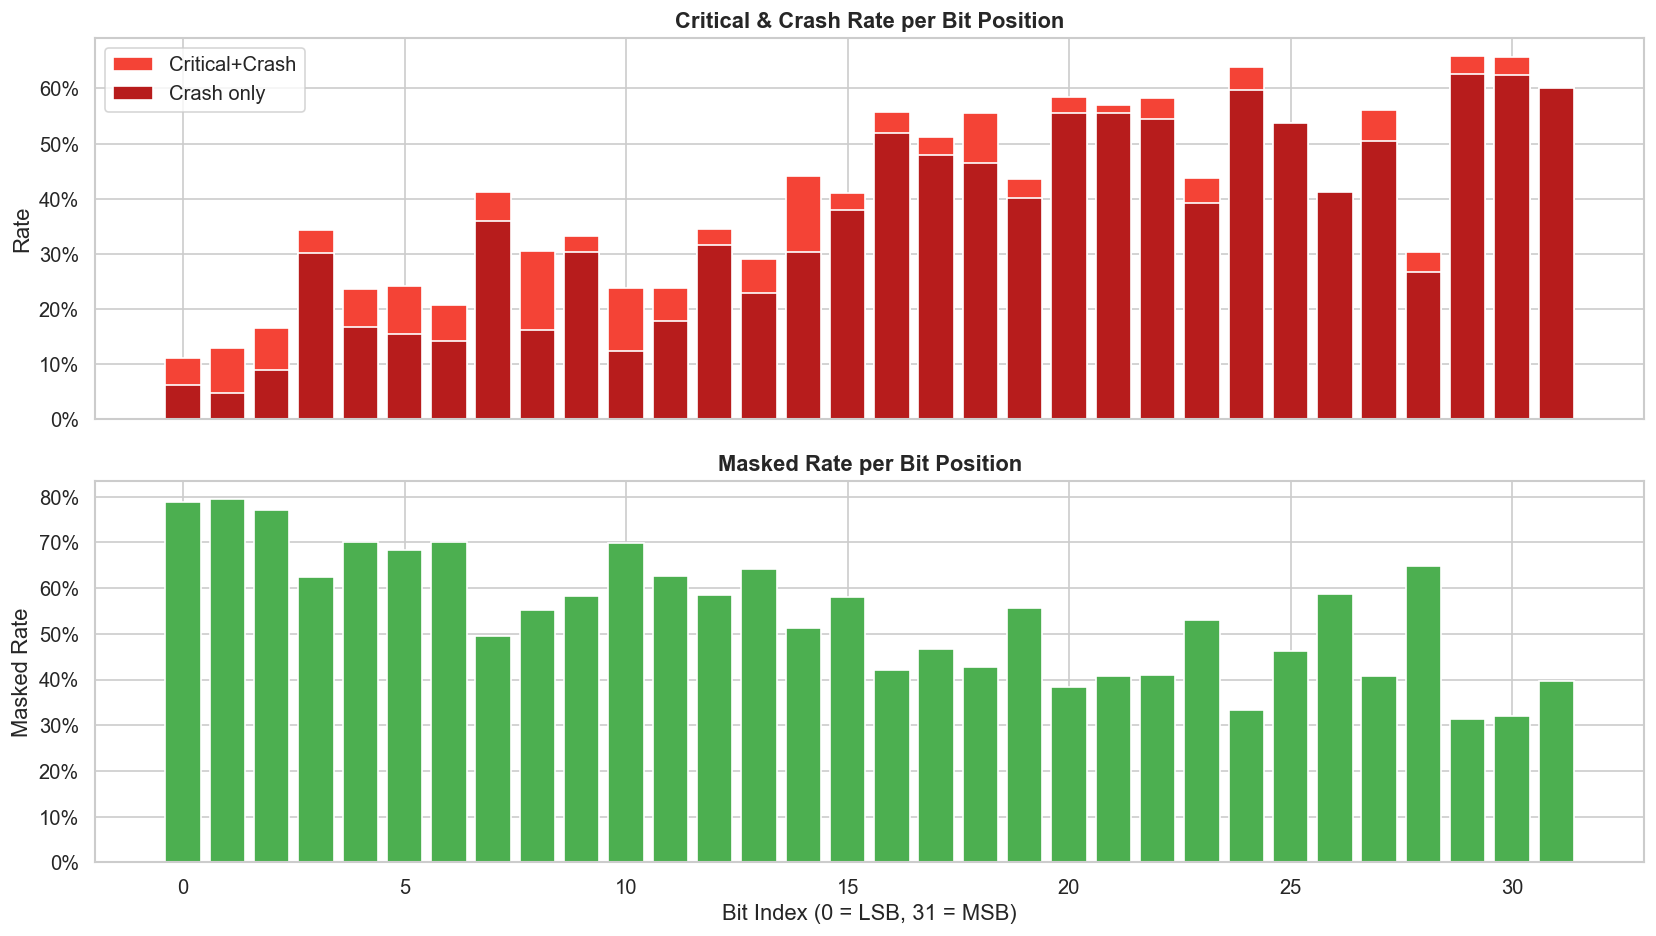

,bit_index,total,critical,degraded,crash,masked,critical_rate,crash_rate,masked_rate
0,0,3300,368,522,203,2599,0.1115,0.0615,0.7876
1,1,3000,390,533,142,2385,0.1300,0.0473,0.7950
2,2,2400,396,440,216,1849,0.1650,0.0900,0.7704
3,3,3000,1028,1050,907,1872,0.3427,0.3023,0.6240
4,4,2400,566,609,400,1682,0.2358,0.1667,0.7008
5,5,2600,627,725,400,1777,0.2412,0.1538,0.6835
6,6,2900,601,727,412,2030,0.2072,0.1421,0.7000
7,7,2800,1156,1273,1008,1386,0.4129,0.3600,0.4950
8,8,1900,579,709,308,1050,0.3047,0.1621,0.5526
9,9,2300,764,833,697,1341,0.3322,0.3030,0.5830


In [15]:
bit_fc = df.groupby("bit_index").apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "degraded": g["fault_class"].isin(DEGRADED_SET).sum(),
        "crash": (g["fault_class"] == "Crash").sum(),
        "masked": (g["fault_class"] == "Masked").sum(),
    })
).reset_index()
bit_fc["bit_index"] = bit_fc["bit_index"].astype(int)
bit_fc["critical_rate"] = bit_fc["critical"] / bit_fc["total"]
bit_fc["crash_rate"] = bit_fc["crash"] / bit_fc["total"]
bit_fc["masked_rate"] = bit_fc["masked"] / bit_fc["total"]
bit_fc = bit_fc.sort_values("bit_index")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].bar(bit_fc["bit_index"], bit_fc["critical_rate"], color="#F44336", label="Critical+Crash")
axes[0].bar(bit_fc["bit_index"], bit_fc["crash_rate"], color="#B71C1C", label="Crash only")
axes[0].set_ylabel("Rate")
axes[0].set_title("Critical & Crash Rate per Bit Position", fontweight="bold")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[1].bar(bit_fc["bit_index"], bit_fc["masked_rate"], color="#4CAF50")
axes[1].set_ylabel("Masked Rate")
axes[1].set_xlabel("Bit Index (0 = LSB, 31 = MSB)")
axes[1].set_title("Masked Rate per Bit Position", fontweight="bold")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability.png", bbox_inches="tight")
plt.show()

display(bit_fc.round(4))

## 8. Bit-Position Vulnerability by Register Class

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3218813655.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bit_cls = df.groupby(["register_class", "bit_index"]).apply(


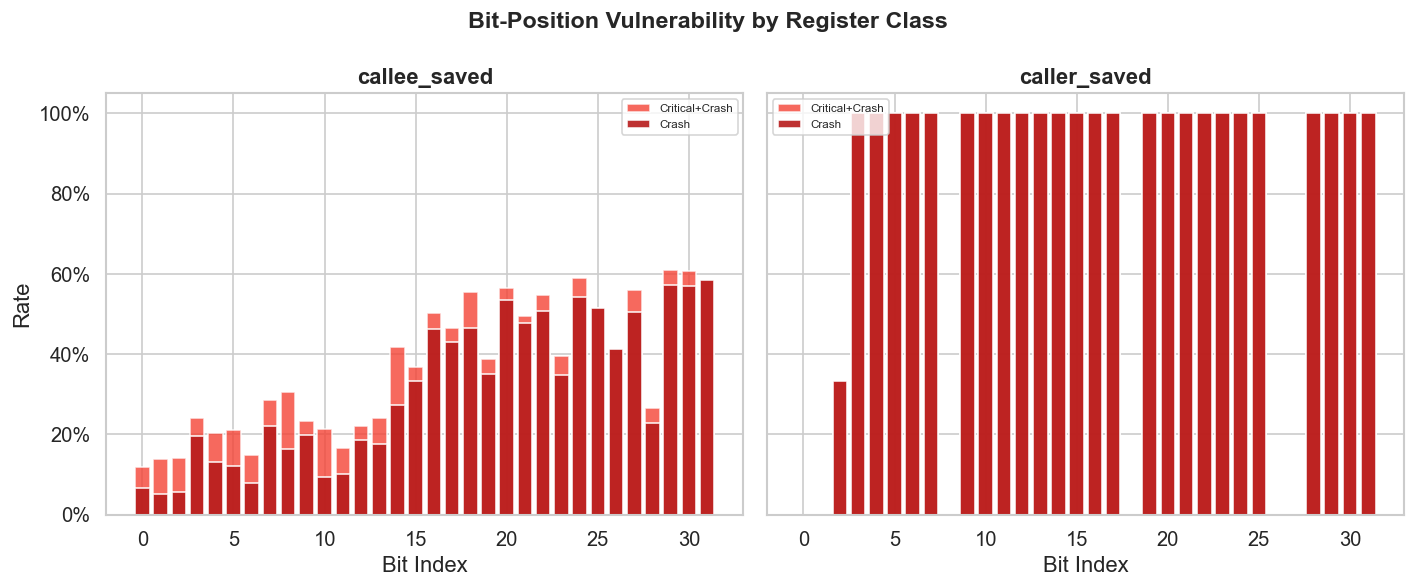

In [16]:
bit_cls = df.groupby(["register_class", "bit_index"]).apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0,
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g) if len(g) > 0 else 0,
    })
).reset_index()
bit_cls["bit_index"] = bit_cls["bit_index"].astype(int)

reg_classes = sorted(bit_cls["register_class"].unique())
fig, axes = plt.subplots(1, len(reg_classes), figsize=(6 * len(reg_classes), 5), sharey=True)
if len(reg_classes) == 1:
    axes = [axes]

for ax, rc in zip(axes, reg_classes):
    subset = bit_cls[bit_cls["register_class"] == rc].sort_values("bit_index")
    ax.bar(subset["bit_index"], subset["critical_rate"], color="#F44336", alpha=0.8, label="Critical+Crash")
    ax.bar(subset["bit_index"], subset["crash_rate"], color="#B71C1C", alpha=0.9, label="Crash")
    ax.set_title(f"{rc}", fontweight="bold")
    ax.set_xlabel("Bit Index")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.legend(fontsize=7)

axes[0].set_ylabel("Rate")
fig.suptitle("Bit-Position Vulnerability by Register Class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability_by_class.png", bbox_inches="tight")
plt.show()

## 9. Crash & Critical Failure Deep-Dive

Total critical/crash inferences: 33,434 (40.53%)
Unique faults causing critical/crash: 430 / 825



fault_class,Crash,Critical,total_critical
register_name,,,
ra,5900,0,5900
s3,3741,590,4331
s8,2615,583,3198
s0,2775,422,3197
s2,1800,1186,2986
s11,2506,115,2621
s9,2440,0,2440
s1,1900,415,2315
s10,1971,224,2195


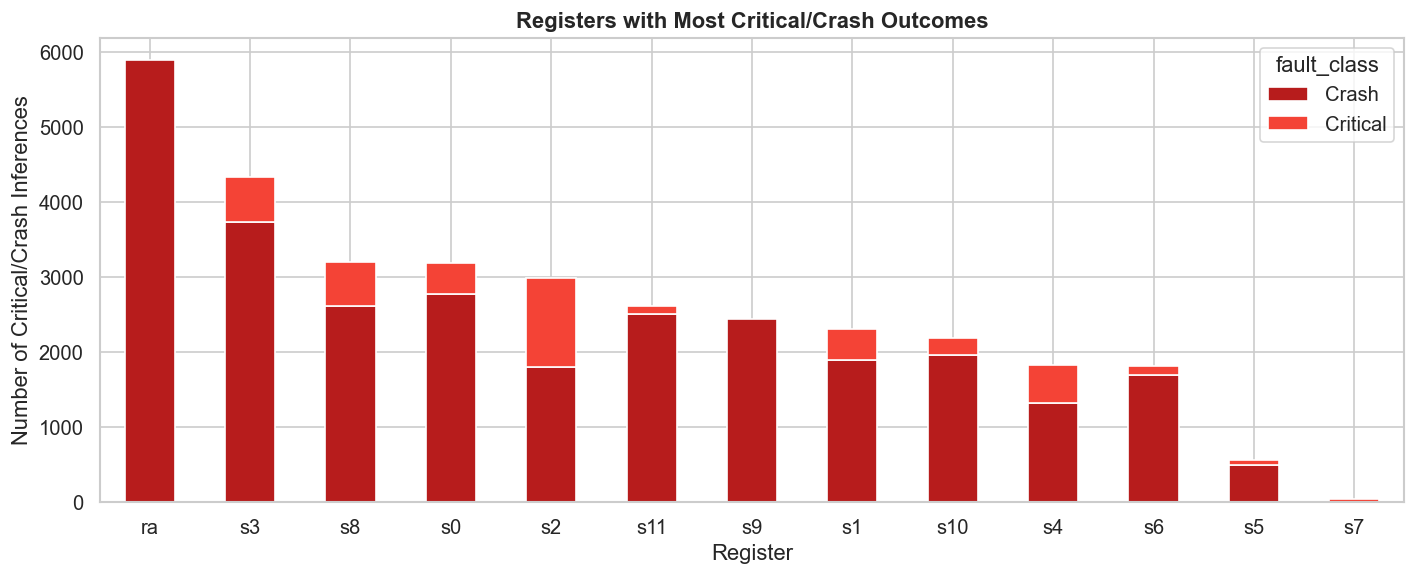

In [29]:
crit_df = df[df["fault_class"].isin(CRITICAL_SET)].copy()
print(f"Total critical/crash inferences: {len(crit_df):,} ({len(crit_df)/len(df)*100:.2f}%)")
print(f"Unique faults causing critical/crash: {crit_df['fault_id'].nunique()} / {df['fault_id'].nunique()}")
print()

# Which registers cause the most crashes?
crash_by_reg = crit_df.groupby("register_name")["fault_class"].value_counts().unstack(fill_value=0)
crash_by_reg["total_critical"] = crash_by_reg.sum(axis=1)
crash_by_reg = crash_by_reg.sort_values("total_critical", ascending=False)
display(crash_by_reg.head(15))

# Top 10 most critical registers
fig, ax = plt.subplots(figsize=(12, 5))
top_crit_regs = crash_by_reg.head(15)
colors_stacked = []
for c in top_crit_regs.columns:
    if c == "total_critical":
        continue
    colors_stacked.append(SEVERITY_COLORS.get(c, "#999"))

plot_cols = [c for c in top_crit_regs.columns if c != "total_critical"]
top_crit_regs[plot_cols].plot.bar(stacked=True, ax=ax, color=colors_stacked, edgecolor="white")
ax.set_ylabel("Number of Critical/Crash Inferences")
ax.set_xlabel("Register")
ax.set_title("Registers with Most Critical/Crash Outcomes", fontweight="bold")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_crash_by_register.png", bbox_inches="tight")
plt.show()

## 10. Per-Fault Aggregated Vulnerability
For each unique fault injection, compute the fraction of images that were classified as critical/crash to identify the **most dangerous single-bit faults**.

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\504302691.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fault_agg = df.groupby("fault_id").apply(


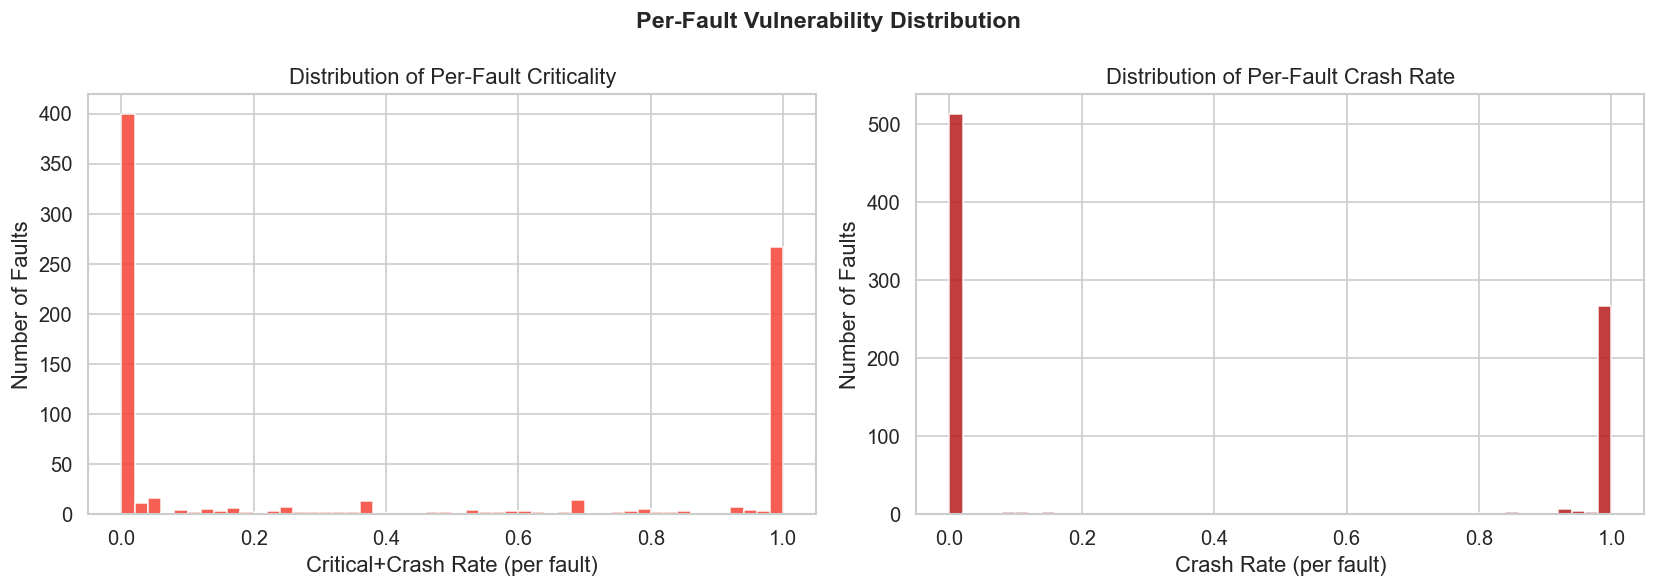


Top 20 most dangerous faults (by critical_rate):


,fault_id,register_name,register_class,bit_index,operator_index,operator_name,n_images,n_critical,n_crash,critical_rate,crash_rate
1,3.0,ra,caller_saved,3,0,CONV_2D,100,100,100,1.0,1.0
2,6.0,ra,caller_saved,6,0,CONV_2D,100,100,100,1.0,1.0
3,7.0,ra,caller_saved,7,0,CONV_2D,100,100,100,1.0,1.0
4,9.0,ra,caller_saved,9,0,CONV_2D,100,100,100,1.0,1.0
5,11.0,ra,caller_saved,11,0,CONV_2D,100,100,100,1.0,1.0
6,12.0,ra,caller_saved,12,0,CONV_2D,100,100,100,1.0,1.0
7,13.0,ra,caller_saved,13,0,CONV_2D,100,100,100,1.0,1.0
8,23.0,ra,caller_saved,23,0,CONV_2D,100,100,100,1.0,1.0
9,24.0,ra,caller_saved,24,0,CONV_2D,100,100,100,1.0,1.0
10,29.0,ra,caller_saved,29,0,CONV_2D,100,100,100,1.0,1.0


In [30]:
fault_agg = df.groupby("fault_id").apply(
    lambda g: pd.Series({
        "register_name": g["register_name"].iloc[0],
        "register_class": g["register_class"].iloc[0],
        "bit_index": int(g["bit_index"].iloc[0]),
        "operator_index": int(g["operator_index"].iloc[0]),
        "operator_name": g["operator_name"].iloc[0] if "operator_name" in g.columns else "",
        "n_images": len(g),
        "n_critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "n_crash": (g["fault_class"] == "Crash").sum(),
        "n_masked": (g["fault_class"] == "Masked").sum(),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g),
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g),
    })
).reset_index()

# Distribution of per-fault critical rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fault_agg["critical_rate"], bins=50, color="#F44336", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Critical+Crash Rate (per fault)")
axes[0].set_ylabel("Number of Faults")
axes[0].set_title("Distribution of Per-Fault Criticality")

axes[1].hist(fault_agg["crash_rate"], bins=50, color="#B71C1C", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Crash Rate (per fault)")
axes[1].set_ylabel("Number of Faults")
axes[1].set_title("Distribution of Per-Fault Crash Rate")

fig.suptitle("Per-Fault Vulnerability Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_per_fault_distribution.png", bbox_inches="tight")
plt.show()

# Top 20 most dangerous faults
print("\nTop 20 most dangerous faults (by critical_rate):")
display(fault_agg.nlargest(20, "critical_rate")[
    ["fault_id", "register_name", "register_class", "bit_index",
     "operator_index", "operator_name", "n_images", "n_critical",
     "n_crash", "critical_rate", "crash_rate"]
])

## 11. Crash-Inference Bias Analysis

The `inferred` column flags rows that were **not actually dispatched** to the device: after the
configured `crash_inference_threshold` (T) consecutive crashes on the same `fault_id`, the
campaign synthesizes the remaining images as `Crash` rows to save the (expensive) recovery cost.

This section quantifies how much of the dataset is *measured* vs *synthesized* and where in the
per-fault image sequence inference kicks in — a useful sanity check on the threshold setting and a
proxy for how much extra signal a larger `T` (or `T=0`, fully dispatched) would add.

In [35]:
# --- Normalize inferred column (string "True"/"False" or bool) -------------
if "inferred" not in df.columns:
    raise KeyError("Column 'inferred' not found in classified_results.csv")

inf_series = df["inferred"]
if inf_series.dtype == object:
    inf_mask = inf_series.astype(str).str.lower().eq("true")
else:
    inf_mask = inf_series.astype(bool)

df_inf = df.assign(_inferred=inf_mask)

# --- Aggregate per fault ---------------------------------------------------
per_fault = df_inf.groupby("fault_id").agg(
    n_rows=("image_id", "size"),
    n_inferred=("_inferred", "sum"),
    register_name=("register_name", "first"),
    register_class=("register_class", "first"),
    bit_index=("bit_index", "first"),
)
per_fault["has_inferred"] = per_fault["n_inferred"] > 0

# image_id where inference kicked in (first inferred row per fault)
first_inf = (
    df_inf[df_inf["_inferred"]]
    .groupby("fault_id")["image_id"]
    .min()
    .rename("first_inferred_image")
)
per_fault = per_fault.join(first_inf)

n_rows_total = len(df_inf)
n_rows_inf = int(inf_mask.sum())
n_rows_real = n_rows_total - n_rows_inf
n_faults = len(per_fault)
n_faults_inf = int(per_fault["has_inferred"].sum())

print(f"Total result rows                  : {n_rows_total:,}")
print(f"  Real (dispatched)                : {n_rows_real:,}  "
      f"({100.0 * n_rows_real / n_rows_total:5.2f}%)")
print(f"  Inferred (synthesized)           : {n_rows_inf:,}  "
      f"({100.0 * n_rows_inf / n_rows_total:5.2f}%)")
print(f"Total faults                       : {n_faults:,}")
print(f"  Faults w/ >=1 inferred row       : {n_faults_inf:,}  "
      f"({100.0 * n_faults_inf / n_faults:5.2f}%)")
if n_faults_inf:
    print(f"  First-inferred image_id (median) : "
          f"{per_fault['first_inferred_image'].median():.1f}")
    print(f"  First-inferred image_id (mean)   : "
          f"{per_fault['first_inferred_image'].mean():.2f}")

Total result rows                  : 82,500
  Real (dispatched)                : 54,988  (66.65%)
  Inferred (synthesized)           : 27,512  (33.35%)
Total faults                       : 825
  Faults w/ >=1 inferred row       : 293  (35.52%)
  First-inferred image_id (median) : 4.0
  First-inferred image_id (mean)   : 6.10


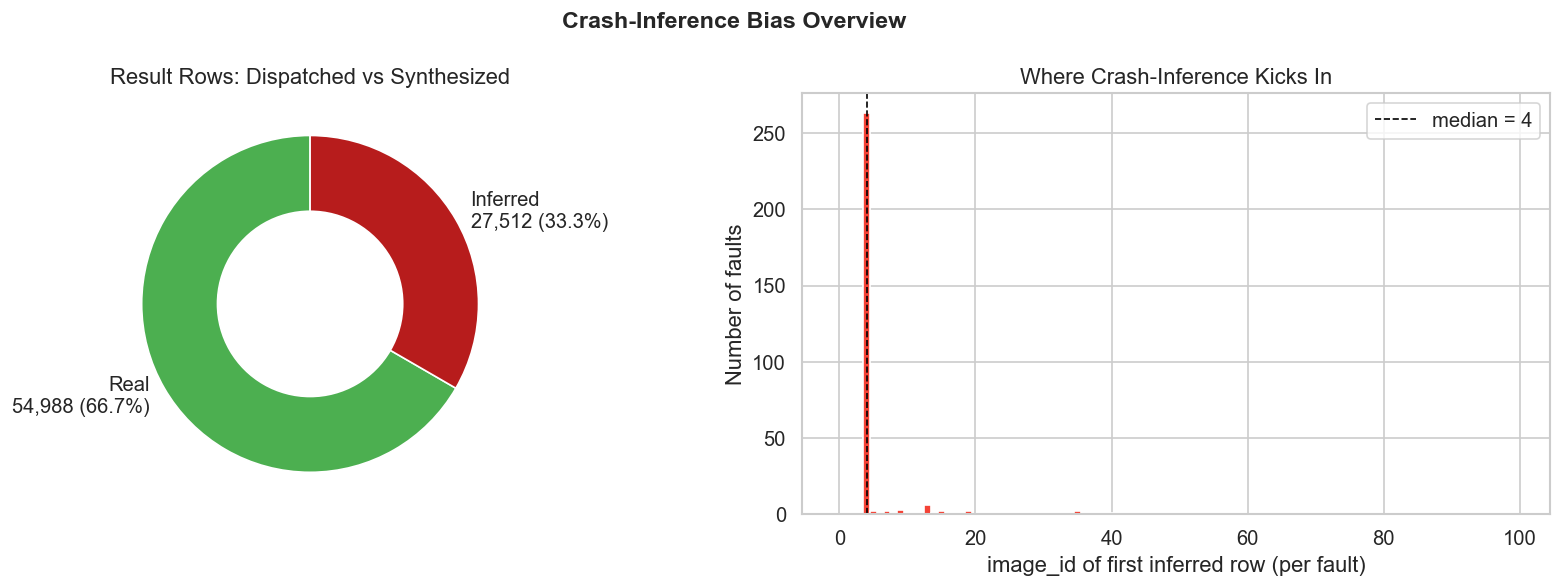

In [36]:
# --- Plots: inferred-row share, first-inferred image_id distribution ------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Donut: real vs inferred rows
shares = [n_rows_real, n_rows_inf]
labels = [
    f"Real\n{n_rows_real:,} ({100.0*n_rows_real/n_rows_total:.1f}%)",
    f"Inferred\n{n_rows_inf:,} ({100.0*n_rows_inf/n_rows_total:.1f}%)",
]
axes[0].pie(
    shares,
    labels=labels,
    colors=["#4CAF50", "#B71C1C"],
    startangle=90,
    wedgeprops=dict(width=0.45, edgecolor="white"),
)
axes[0].set_title("Result Rows: Dispatched vs Synthesized")

# (b) Histogram of image_id where inference started, per fault
if n_faults_inf:
    first_img = per_fault["first_inferred_image"].dropna().astype(int)
    img_max = int(df_inf["image_id"].max())
    bins = np.arange(0, img_max + 2) - 0.5
    axes[1].hist(first_img, bins=bins, color="#F44336", edgecolor="white")
    axes[1].set_xlabel("image_id of first inferred row (per fault)")
    axes[1].set_ylabel("Number of faults")
    axes[1].set_title("Where Crash-Inference Kicks In")
    axes[1].axvline(
        first_img.median(),
        color="black", linestyle="--", linewidth=1,
        label=f"median = {first_img.median():.0f}",
    )
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, "No inferred rows in this run",
                 ha="center", va="center", transform=axes[1].transAxes)
    axes[1].set_axis_off()

fig.suptitle("Crash-Inference Bias Overview", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_inferred_bias_overview.png", bbox_inches="tight")
plt.show()

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3058668336.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_pct_faults_with_inference)
C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3058668336.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_pct_faults_with_inference)
C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3058668336.py:40: DeprecationWarning: DataFrameGroupBy.apply o

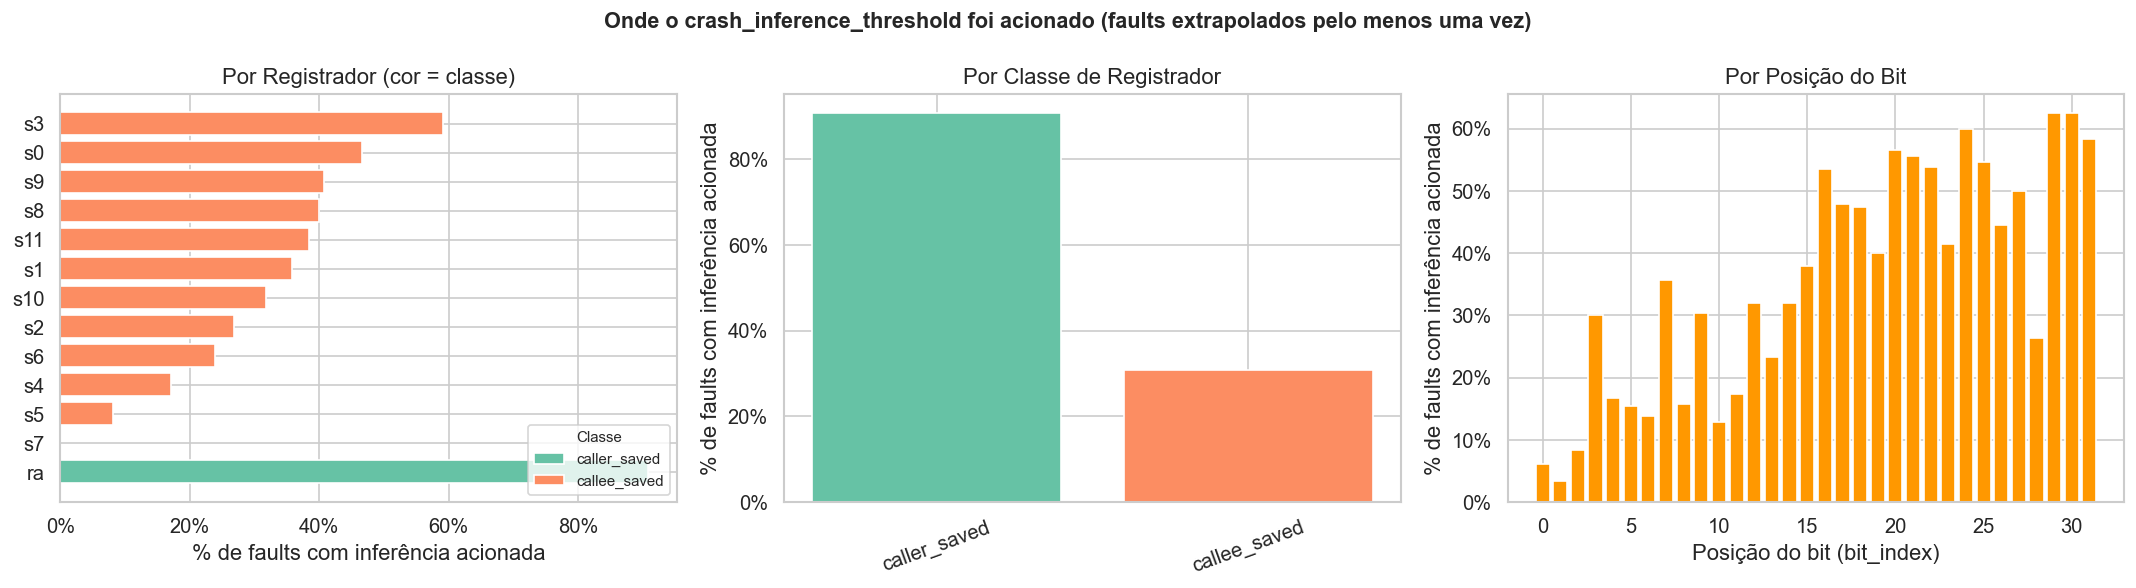


Top 15 registradores com maior % de faults extrapolados:


,pct_faults_inferred,register_class
register_name,,
s3,59.090909,callee_saved
s0,46.666667,callee_saved
s9,40.677966,callee_saved
s8,40.000000,callee_saved
s11,38.461538,callee_saved
s1,35.849057,callee_saved
s10,31.818182,callee_saved
s2,26.865672,callee_saved
s6,23.943662,callee_saved


In [ ]:
# --- Where crash-inference was triggered: per register, class and bit ------
# For each register / class / bit we compute:
#   "% of faults with crash-inference triggered"
#   = fraction of faults in that group where at least one image was
#     synthesized as Crash by the crash_inference_threshold mechanism
#     (instead of actually being dispatched and measured on the chip).
# Higher value => the framework "short-circuited" more faults in that
# group, treating them as deterministic crashers.
def _pct_faults_with_inference(group: pd.DataFrame) -> float:
    return 100.0 * group["has_inferred"].mean()

YLABEL_PCT = "% of faults with crash-inference triggered"

# Pretty, visually distinct labels for register classes
# (raw values 'caller_saved' / 'callee_saved' differ by a single letter
#  and are easy to misread on a legend).
CLASS_LABELS = {
    "caller_saved": "Caller-saved (volatile)",
    "callee_saved": "Callee-saved (preserved)",
}

def _class_label(c: str) -> str:
    return CLASS_LABELS.get(c, c)

# Per register, annotated with its class (for color + grouping)
reg_class_map = (
    per_fault.reset_index()
    .drop_duplicates("register_name")
    .set_index("register_name")["register_class"]
)
by_reg = (
    per_fault.groupby("register_name")
    .apply(_pct_faults_with_inference)
    .rename("pct_faults_inferred")
    .to_frame()
)
by_reg["register_class"] = reg_class_map
# Sort by class, then by % within class (descending)
by_reg = by_reg.sort_values(
    ["register_class", "pct_faults_inferred"],
    ascending=[True, False],
)

by_cls = (
    per_fault.groupby("register_class")
    .apply(_pct_faults_with_inference)
    .sort_values(ascending=False)
    .rename("pct_faults_inferred")
)
by_bit = (
    per_fault.groupby("bit_index")
    .apply(_pct_faults_with_inference)
    .sort_index()
    .rename("pct_faults_inferred")
)

# Distinct colors per class, consistent across panels (a) and (b)
classes_ordered = list(by_cls.index)
class_palette = {
    "caller_saved": "#1f77b4",  # blue
    "callee_saved": "#d62728",  # red
}
class_color = {
    c: class_palette.get(c, sns.color_palette("Set2", len(classes_ordered))[i])
    for i, c in enumerate(classes_ordered)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Per register, bars colored by register class
bar_colors = [class_color[c] for c in by_reg["register_class"]]
axes[0].barh(by_reg.index, by_reg["pct_faults_inferred"].values,
             color=bar_colors, edgecolor="white")
axes[0].invert_yaxis()
axes[0].set_xlabel(YLABEL_PCT)
axes[0].set_title("Per Register (color = class)")
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=class_color[c], label=_class_label(c))
    for c in classes_ordered
]
axes[0].legend(handles=legend_handles, title="Register class",
               loc="lower right", fontsize=9, title_fontsize=9)

# (b) Per register class (same colors as panel a)
cls_labels = [_class_label(c) for c in by_cls.index]
axes[1].bar(cls_labels, by_cls.values,
            color=[class_color[c] for c in by_cls.index],
            edgecolor="white")
axes[1].set_ylabel(YLABEL_PCT)
axes[1].set_title("Per Register Class")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
for tick in axes[1].get_xticklabels():
    tick.set_rotation(15)
    tick.set_ha("right")

# (c) Per bit position
axes[2].bar(by_bit.index.astype(int), by_bit.values,
            color="#FF9800", edgecolor="white")
axes[2].set_xlabel("Bit position (bit_index)")
axes[2].set_ylabel(YLABEL_PCT)
axes[2].set_title("Per Bit Position")
axes[2].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

fig.suptitle(
    "Crash-Inference Incidence "
    "(faults extrapolated at least once by crash_inference_threshold)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_inferred_bias_breakdown.png", bbox_inches="tight")
plt.show()

print("\nTop 15 registers by % of faults with crash-inference triggered:")
display(
    by_reg.head(15)
    .assign(register_class=lambda d: d["register_class"].map(_class_label))
)

## 12. Register × Bit Heatmap (Critical Rate)

C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\2195538395.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reg_bit_crit = df.groupby(["register_name", "bit_index"]).apply(critical_rate).unstack(fill_value=0)


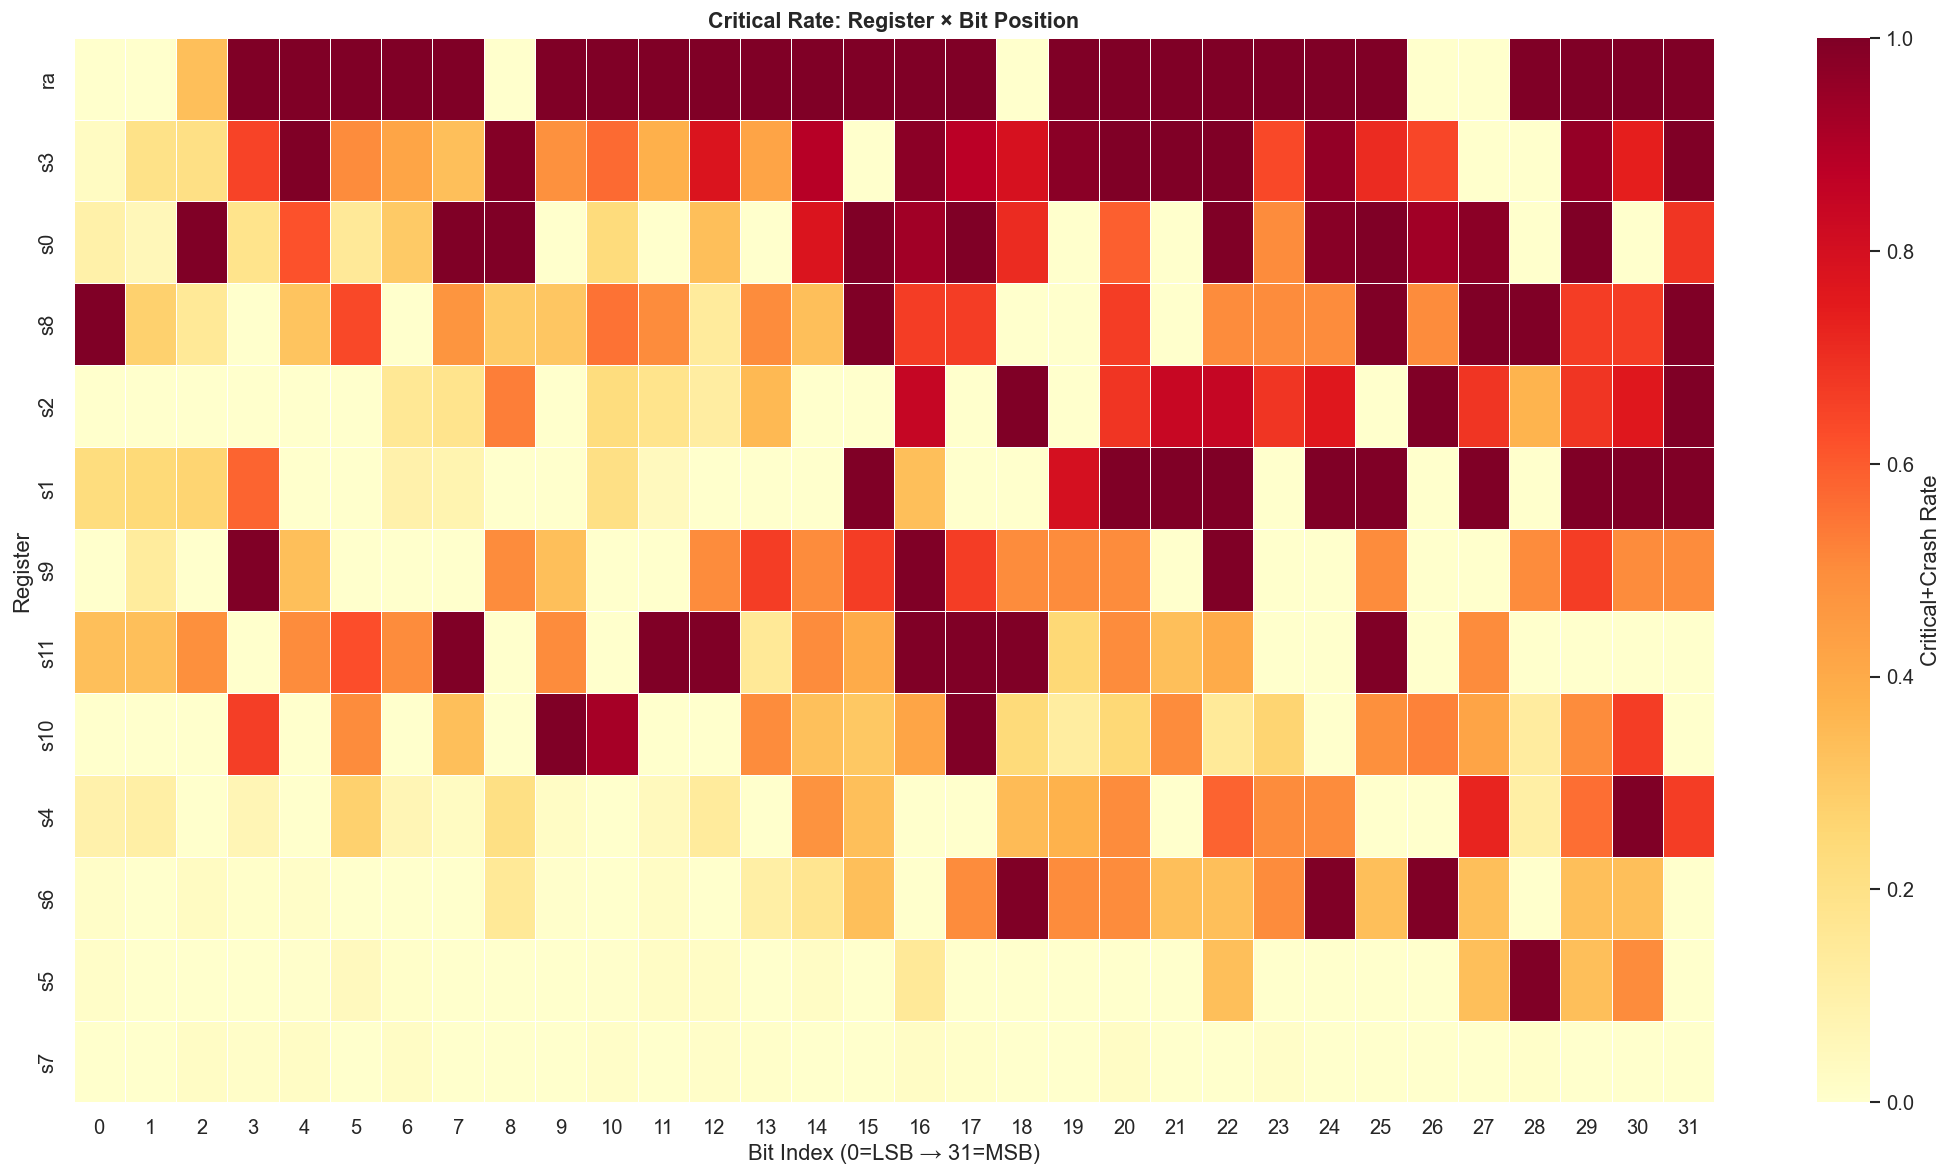

In [38]:
reg_bit_crit = df.groupby(["register_name", "bit_index"]).apply(critical_rate).unstack(fill_value=0)
reg_bit_crit = reg_bit_crit.reindex(reg_order)
reg_bit_crit.columns = reg_bit_crit.columns.astype(int)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(
    reg_bit_crit, cmap="YlOrRd", linewidths=0.3, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical+Crash Rate"},
    vmin=0, vmax=max(reg_bit_crit.max().max(), 0.01),
)
ax.set_title("Critical Rate: Register × Bit Position", fontweight="bold", fontsize=13)
ax.set_ylabel("Register")
ax.set_xlabel("Bit Index (0=LSB → 31=MSB)")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_register_bit.png", bbox_inches="tight")
plt.show()

## 13. Impact on Model Accuracy
Compare the **golden accuracy** (no fault) against the effective accuracy under each fault scenario.

Golden Accuracy : 0.6399 (63.99%)
Faulty Accuracy : 0.5900 (59.00%)
Accuracy Drop   : 4.99 pp


C:\Users\ronal\AppData\Local\Temp\ipykernel_16340\3552998935.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc_per_reg = df.groupby("register_name").apply(


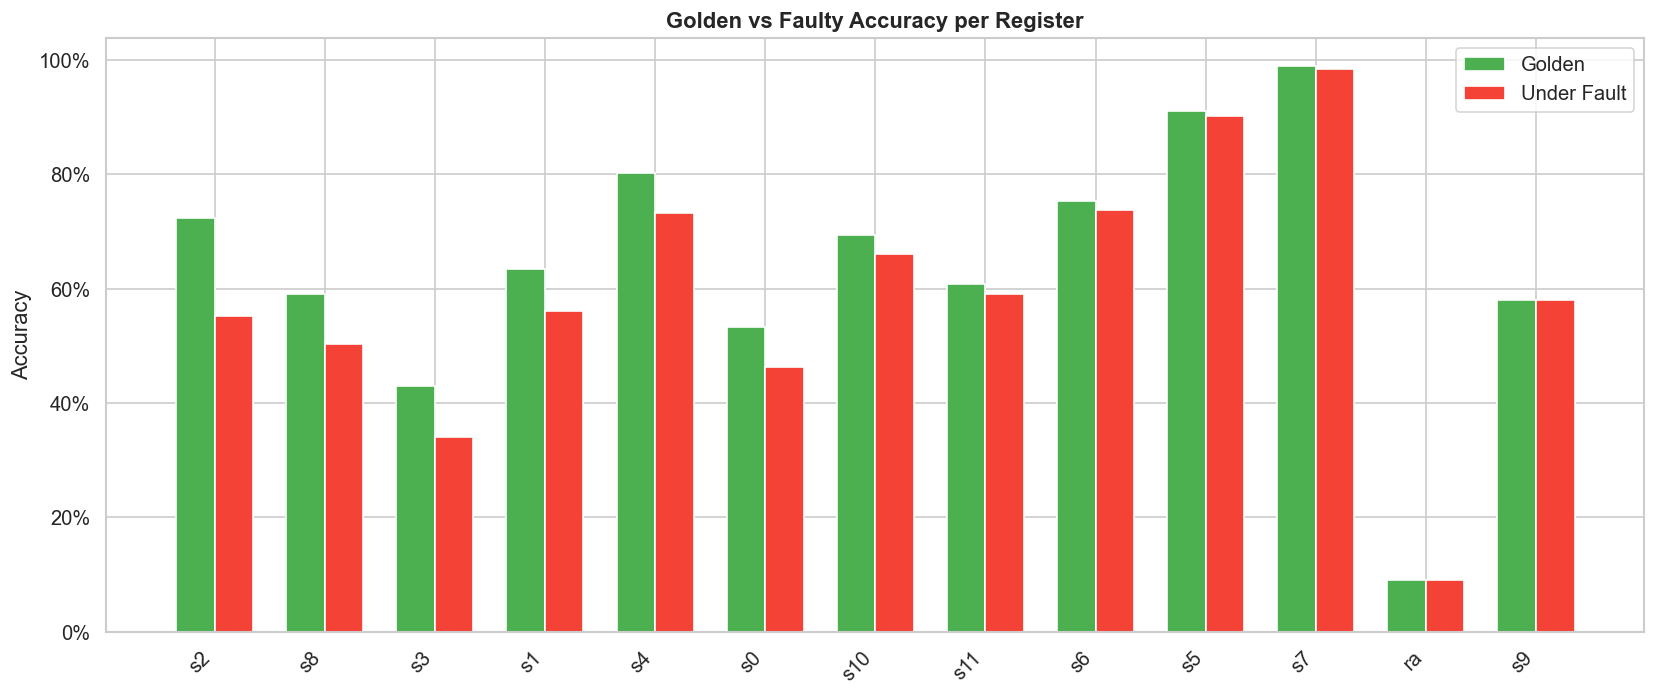

,faulty_accuracy,golden_accuracy,accuracy_drop
register_name,,,
s2,0.5527,0.7240,0.1713
s8,0.5031,0.5917,0.0886
s3,0.3409,0.4291,0.0882
s1,0.5617,0.6351,0.0734
s4,0.7334,0.8024,0.0690
s0,0.4640,0.5323,0.0683
s10,0.6614,0.6945,0.0332
s11,0.5909,0.6083,0.0174
s6,0.7375,0.7530,0.0155


In [39]:
# Golden accuracy
golden_correct = (df["golden_pred_class_ref"] == df["label"]).sum()
golden_acc = golden_correct / len(df)

# Faulty accuracy
faulty_correct = (df["pred_class"] == df["label"]).sum()
faulty_acc = faulty_correct / len(df)

print(f"Golden Accuracy : {golden_acc:.4f} ({golden_acc*100:.2f}%)")
print(f"Faulty Accuracy : {faulty_acc:.4f} ({faulty_acc*100:.2f}%)")
print(f"Accuracy Drop   : {(golden_acc - faulty_acc)*100:.2f} pp")

# Accuracy per register
acc_per_reg = df.groupby("register_name").apply(
    lambda g: pd.Series({
        "faulty_accuracy": (g["pred_class"] == g["label"]).sum() / len(g),
        "golden_accuracy": (g["golden_pred_class_ref"] == g["label"]).sum() / len(g),
        "accuracy_drop": ((g["golden_pred_class_ref"] == g["label"]).sum() - (g["pred_class"] == g["label"]).sum()) / len(g),
    })
).sort_values("accuracy_drop", ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(acc_per_reg))
w = 0.35
ax.bar(x - w/2, acc_per_reg["golden_accuracy"], w, label="Golden", color="#4CAF50", edgecolor="white")
ax.bar(x + w/2, acc_per_reg["faulty_accuracy"], w, label="Under Fault", color="#F44336", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(acc_per_reg.index, rotation=45, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Golden vs Faulty Accuracy per Register", fontweight="bold")
ax.legend()
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_accuracy_per_register.png", bbox_inches="tight")
plt.show()

display(acc_per_reg.round(4))

## 14. Probability (Confidence) Degradation Analysis
For non-crash inferences, measure how fault injection affected the output confidence.

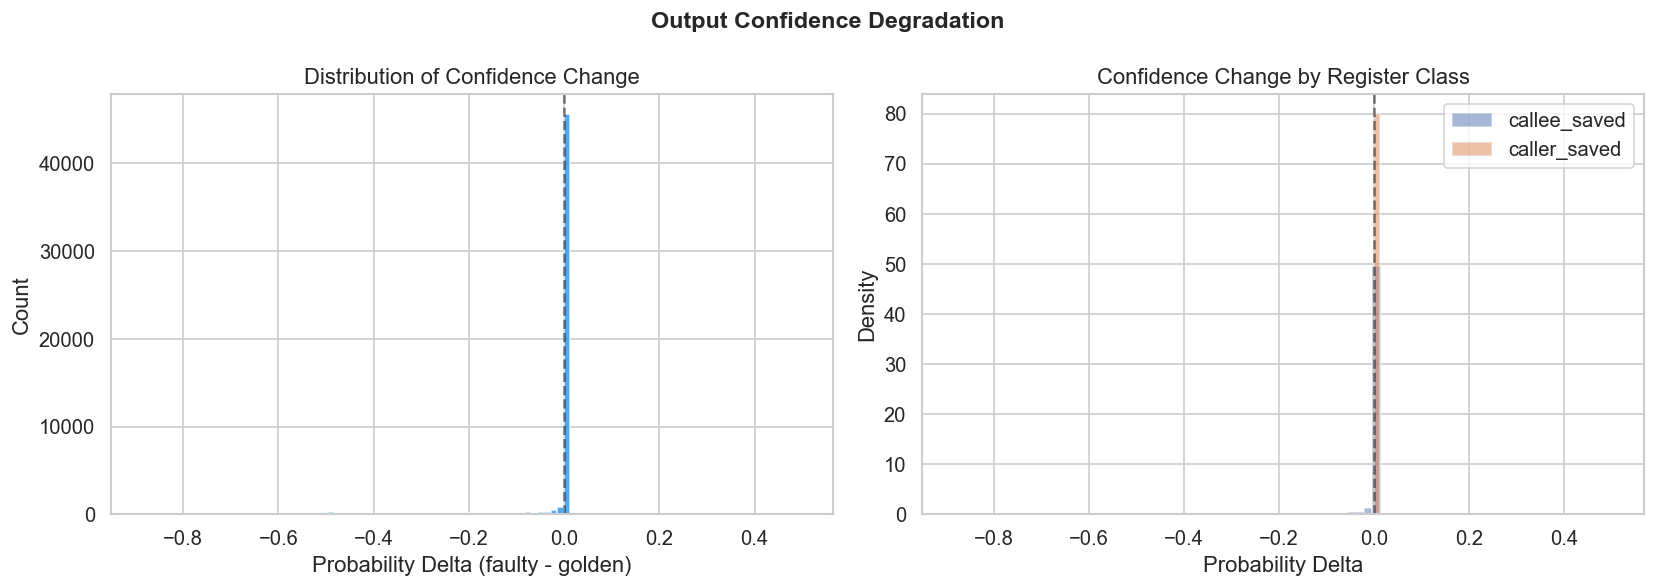

,mean,std,min,max
register_name,,,,
s2,-0.1079,0.1793,-0.6719,0.4531
s3,-0.0946,0.2258,-0.8320,0.4961
s0,-0.0666,0.1695,-0.7773,0.4727
s1,-0.0615,0.1614,-0.8086,0.4609
s4,-0.0501,0.1556,-0.8828,0.4961
s8,-0.0365,0.1117,-0.6758,0.4961
s11,-0.0088,0.0592,-0.6797,0.4883
s6,-0.0074,0.0544,-0.6367,0.4844
s5,-0.0024,0.0323,-0.5703,0.4766


In [40]:
ok_df = df[df["status"] == "ok"].copy()
ok_df["prob_delta"] = ok_df["top1_prob"] - ok_df["golden_top1_prob_ref"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ok_df["prob_delta"], bins=100, color="#2196F3", edgecolor="white", alpha=0.8)
axes[0].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Probability Delta (faulty - golden)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Confidence Change")

# Per register class
for rc in sorted(ok_df["register_class"].dropna().unique()):
    subset = ok_df[ok_df["register_class"] == rc]["prob_delta"]
    axes[1].hist(subset, bins=80, alpha=0.5, label=rc, density=True)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Probability Delta")
axes[1].set_ylabel("Density")
axes[1].set_title("Confidence Change by Register Class")
axes[1].legend()

fig.suptitle("Output Confidence Degradation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_confidence_degradation.png", bbox_inches="tight")
plt.show()

# Mean confidence delta per register
prob_stats = ok_df.groupby("register_name")["prob_delta"].agg(["mean", "std", "min", "max"]).sort_values("mean")
display(prob_stats.round(4))

## 15. Summary Table (LaTeX-ready)
Consolidated table for the paper.

## 16. Per Register-Class Summary (LaTeX-ready)

## 17. Export Analysis Artifacts